# 01  - Ingestion with Docling

Turning raw annual-report PDFs into labeled pieces (**text chunks, tables, charts**), each tagged with company, fiscal year and page, saved to Google Drive.

**Key steps**
- Classifying every page as digital / scanned / mixed and routing it to the right OCR setting
- Docling layout + TableFormer table-structure models, structure-aware chunking (512-token limit of bge-small)
- Processing in 40-page batches checkpointed to Drive, so RAM stays flat and a crash only loses one batch

**Built to scale:** add any number of companies and years under `reports/<company>/<year>.pdf`. Processing is per report, batched and cached, so new reports are added incrementally without reprocessing old ones.

**Runtime:** T4 GPU.

## Setup
Installing the required libraries (EasyOCR is the OCR engine Docling uses for scanned pages).

In [ ]:
# Installing libraries
!pip install -q docling pymupdf pandas easyocr

- **Docling** is IBM's open-source document parser: a layout model finds text, tables and pictures on each page, and TableFormer rebuilds table rows and columns.
- **PyMuPDF** (`fitz`) is a fast, low-level PDF toolkit used for page checks and rendering.

## Mounting Drive and setting paths

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

PROJECT_DIR   = Path("/content/drive/MyDrive/annual-report-rag")
REPORTS_DIR   = PROJECT_DIR / "reports"       # reports/<company>/<year>.pdf
PROCESSED_DIR = PROJECT_DIR / "processed"     # one JSON per report
IMAGES_DIR    = PROJECT_DIR / "images"        # chart + table images

for d in [REPORTS_DIR, PROCESSED_DIR, IMAGES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

In [3]:
# Checking which reports are already processed (and deleting any half-written file)
import json
done = sorted(PROCESSED_DIR.glob("*.json"))
print(f"{len(done)} reports fully processed:")
for f in done:
    try:
        n = len(json.loads(f.read_text()))
        print(f" {f.stem}: {n} elements")
    except Exception:
        print(f"{f.stem}: file is broken, deleting it so it gets redone")
        f.unlink()

3 reports fully processed:
 au_small_finance_bank_2023: 1422 elements
 au_small_finance_bank_2024: 1538 elements
 au_small_finance_bank_2025: 1561 elements


Organizing loose PDFs into `reports/<company>/<year>.pdf` (only for files placed directly in `reports/`)

In [4]:
import re, shutil

for pdf in REPORTS_DIR.glob("*.pdf"):
    year = re.search(r"(20\d{2})", pdf.stem)
    if not year:
        print(f"no year found in: {pdf.name}, renaming this one by hand")
        continue
    company = pdf.stem.split("_")[0].split(" ")[0].lower()
    target = REPORTS_DIR / company / f"{year.group(1)}.pdf"
    target.parent.mkdir(exist_ok=True)
    shutil.move(str(pdf), str(target))
    print(f"{pdf.name}  -  {company}/{target.name}")

Listing the reports

In [5]:
pdfs = sorted(REPORTS_DIR.glob("*/*.pdf"))
print(f"Found {len(pdfs)} PDFs")
for p in pdfs:
    print(" ", p.relative_to(REPORTS_DIR))

Found 3 PDFs
  au_small_finance_bank/2023.pdf
  au_small_finance_bank/2024.pdf
  au_small_finance_bank/2025.pdf


Building the metadata table and classifying each report as digital / scanned / mixed

In [7]:
!pip install -q docling pymupdf pandas easyocr

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 992.9/992.9 kB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 70.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 98.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 67.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.8/317.8 kB 31.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 94.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.1/183.1 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.6/62.6 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [9]:
import pymupdf as fitz  # PyMuPDF

In [10]:
import fitz  # PyMuPDF
import pandas as pd

def classify_pdf(path, min_chars=50):
    """Count pages with almost no extractable text (= scanned images)."""
    with fitz.open(path) as d:
        n = d.page_count
        scanned_pages = sum(1 for page in d if len(page.get_text().strip()) < min_chars)
    ratio = scanned_pages / n
    mode = "digital" if ratio < 0.1 else "scanned" if ratio > 0.8 else "mixed"
    return n, round(ratio, 2), mode

rows = []
for pdf in pdfs:
    company, year = pdf.parent.name, pdf.stem
    n_pages, scanned_ratio, mode = classify_pdf(pdf)
    rows.append({
        "doc_id": f"{company}_{year}",
        "company": company,
        "year": year,
        "path": str(pdf),
        "pages": n_pages,
        "scanned_ratio": scanned_ratio,
        "parse_mode": mode,
        "size_mb": round(pdf.stat().st_size / 1e6, 1),
    })

meta = pd.DataFrame(rows)
meta.to_csv(PROJECT_DIR / "metadata.csv", index=False)
print(meta["parse_mode"].value_counts(), "\n")
meta

parse_mode
digital    3
Name: count, dtype: int64 



,doc_id,company,year,path,pages,scanned_ratio,parse_mode,size_mb
0,au_small_finance_bank_2023,au_small_finance_bank,2023,/content/drive/MyDrive/annual-report-rag/repor...,331,0.02,digital,17.9
1,au_small_finance_bank_2024,au_small_finance_bank,2024,/content/drive/MyDrive/annual-report-rag/repor...,179,0.01,digital,22.6
2,au_small_finance_bank_2025,au_small_finance_bank,2025,/content/drive/MyDrive/annual-report-rag/repor...,182,0.00,digital,16.9


## Creating one Docling converter per parse mode (OCR only where needed)

In [11]:
from docling.document_converter import DocumentConverter, PdfFormatOption
from docling.datamodel.base_models import InputFormat
from docling.datamodel.pipeline_options import (
    PdfPipelineOptions, TableFormerMode, EasyOcrOptions
)

def build_converter(mode):
    opts = PdfPipelineOptions()
    opts.do_table_structure = True
    opts.table_structure_options.mode = TableFormerMode.ACCURATE
    opts.generate_picture_images = True
    opts.generate_table_images = True
    opts.images_scale = 2.0

    if mode == "digital":
        opts.do_ocr = False
        opts.table_structure_options.do_cell_matching = True
    else:
        opts.do_ocr = True
        opts.ocr_options = EasyOcrOptions(
            lang=["en"],
            force_full_page_ocr=(mode == "scanned"),   # mixed : OCR only image regions
        )
        opts.table_structure_options.do_cell_matching = False

    return DocumentConverter(
        format_options={InputFormat.PDF: PdfFormatOption(pipeline_options=opts)}
    )

_converters = {}
def get_converter(mode):
    if mode not in _converters:
        _converters[mode] = build_converter(mode)
    return _converters[mode]

print("Converter factory ready")

Converter factory ready


## Creating the structure-aware chunker

In [12]:
from docling.chunking import HybridChunker
from docling_core.types.doc import DocItemLabel
from transformers import AutoTokenizer

EMBED_MODEL_ID = "BAAI/bge-small-en-v1.5"
MAX_TOKENS = 512

try:  # newer docling-core
    from docling_core.transforms.chunker.tokenizer.huggingface import HuggingFaceTokenizer
    tok = HuggingFaceTokenizer(tokenizer=AutoTokenizer.from_pretrained(EMBED_MODEL_ID),
                               max_tokens=MAX_TOKENS)
    chunker = HybridChunker(tokenizer=tok, merge_peers=True)
except ImportError:  # older docling-core
    chunker = HybridChunker(tokenizer=EMBED_MODEL_ID, max_tokens=MAX_TOKENS, merge_peers=True)

print("Chunker ready")

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Chunker ready


## Extraction functions: text chunks, tables, pictures

In [13]:
def extract_text_chunks(doc, m):
    out = []
    for i, chunk in enumerate(chunker.chunk(dl_doc=doc)):
        items = chunk.meta.doc_items
        if all(it.label == DocItemLabel.TABLE for it in items):
            continue                                    # tables handled separately
        text = chunker.contextualize(chunk=chunk)       # adding section headings
        if len(text.strip()) < 50:
            continue
        pages = sorted({p.page_no for it in items for p in it.prov})
        out.append({
            "id": f"{m['doc_id']}_text_{i}",
            "type": "text",
            "doc_id": m["doc_id"], "company": m["company"], "year": m["year"],
            "page": pages[0] if pages else None,
            "headings": chunk.meta.headings or [],
            "content": text,
        })
    return out


def extract_tables(doc, m, img_dir):
    out = []
    for i, table in enumerate(doc.tables):
        if table.data.num_rows < 2 or table.data.num_cols < 2:
            continue
        try:
            md = table.export_to_markdown(doc=doc)
        except TypeError:
            md = table.export_to_markdown()
        tid = f"{m['doc_id']}_table_{i}"

        img_path = None
        img = table.get_image(doc)
        if img is not None:
            img_path = str(img_dir / f"{tid}.png")
            img.save(img_path)

        out.append({
            "id": tid, "type": "table",
            "doc_id": m["doc_id"], "company": m["company"], "year": m["year"],
            "page": table.prov[0].page_no if table.prov else None,
            "caption": table.caption_text(doc) or "",
            "shape": [table.data.num_rows, table.data.num_cols],
            "content": md,
            "image_path": img_path,
        })
    return out


def extract_pictures(doc, m, img_dir, min_side=200, max_aspect=6):
    out, skipped = [], 0
    for i, pic in enumerate(doc.pictures):
        img = pic.get_image(doc)
        if img is None:
            continue
        w, h = img.size
        if min(w, h) < min_side or max(w / h, h / w) > max_aspect:
            skipped += 1                                # logos, icons, banners
            continue
        pid = f"{m['doc_id']}_image_{i}"
        path = img_dir / f"{pid}.png"
        img.save(path)
        out.append({
            "id": pid, "type": "image",
            "doc_id": m["doc_id"], "company": m["company"], "year": m["year"],
            "page": pic.prov[0].page_no if pic.prov else None,
            "caption": pic.caption_text(doc) or "",
            "size": [w, h],
            "content": "",                              # Gemini summary in Notebook 2
            "image_path": str(path),
        })
    print(f"   pictures: kept {len(out)}, skipped {skipped}")
    return out

## Testing on a 10-page slice before the full run

Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (790 > 512). Running this sequence through the model will result in indexing errors



 -----au_small_finance_bank_2023 [digital]-----
10 pages in 23.1s : full report ~ 13 min
   pictures: kept 13, skipped 28
text chunks: 35 | tables: 2 | pictures: 13

Sample chunk: 6 years of banking
With over nearly three decades of experience, first as a NBFC and then as a Bank, we have continuously advanced in our mission to transform into a sustainable, technology-driven, and customer-centric bank. Our unwavering focus on the unserved and underserved retail segment, along with our portfolio of secure lending products, has significantly contributed to the sustainable growth of our balance sheet and rural economies, thereby making a positive impact on the overall economi

Sample table:
 | Key Parameters                                      | FY 2017-18   | FY 2018-19   | FY 2019-20   | FY 2020-21   | FY 2021-22   | FY 2022-23   |
|-----------------------------------------------------|--------------|--------------|--------------|--------------|--------------|--------------|
| No. of S

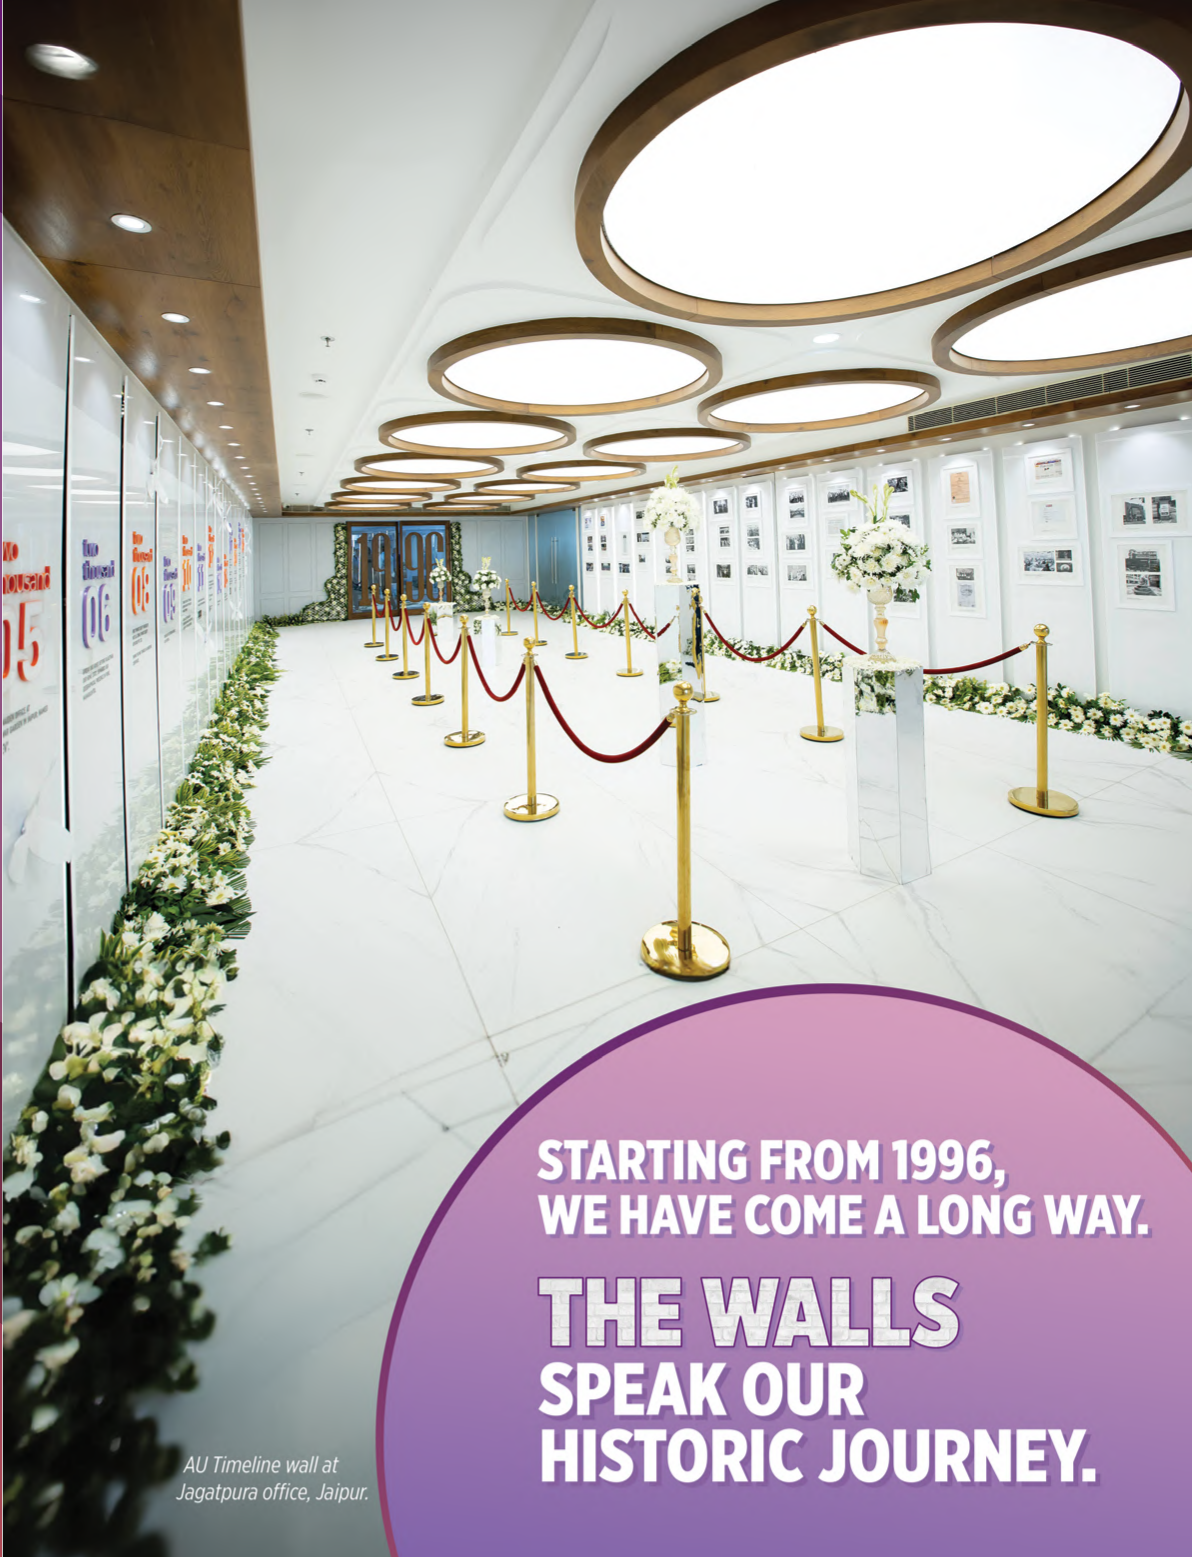

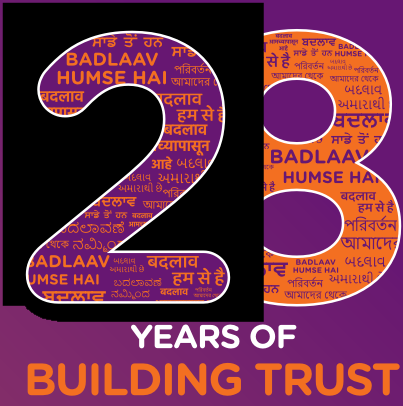

In [14]:
import time
from PIL import Image
from IPython.display import display

def make_test_pdf(path, n_pages, out_path):
    src = fitz.open(path)
    sub = fitz.open()
    sub.insert_pdf(src, from_page=0, to_page=min(n_pages - 1, src.page_count - 1))
    sub.save(out_path)
    return out_path

TEST_DIR = Path("/content/test_images"); TEST_DIR.mkdir(exist_ok=True)

for mode in ["digital", "mixed", "scanned"]:
    subset = meta[meta.parse_mode == mode]
    if subset.empty:
        continue
    row = subset.iloc[0].to_dict()
    test_path = make_test_pdf(row["path"], 10, f"/content/test_{mode}.pdf")

    t0 = time.time()
    doc = get_converter(mode).convert(test_path).document
    secs = time.time() - t0
    print(f"\n -----{row['doc_id']} [{mode}]-----")
    print(f"10 pages in {secs:.1f}s : full report ~ {secs / 10 * row['pages'] / 60:.0f} min")

    txt = extract_text_chunks(doc, row)
    tbl = extract_tables(doc, row, TEST_DIR)
    pic = extract_pictures(doc, row, TEST_DIR)
    print(f"text chunks: {len(txt)} | tables: {len(tbl)} | pictures: {len(pic)}")

    if txt:
        print("\nSample chunk:", txt[min(2, len(txt)-1)]["content"][:500])
    if tbl:
        print("\nSample table:\n", tbl[0]["content"][:800])
    for p in pic[:2]:
        display(Image.open(p["image_path"]))

## Processing all reports in 40-page batches (cached and resumable)
The first full run took ~6 minutes per report with RAM steady at 8-10 GB; this re-run shows every report already cached.

In [15]:
import json, gc, time, torch, psutil

BATCH_PAGES = 40                                  # lower to 20 if it still crashes
PARTS_DIR = PROCESSED_DIR / "_parts"              # per-batch saves, for resuming

def ram():
    return f"RAM {psutil.virtual_memory().used / 1e9:.1f}/{psutil.virtual_memory().total / 1e9:.1f} GB"

def process_report(m):
    out_file = PROCESSED_DIR / f"{m['doc_id']}.json"
    if out_file.exists():
        print(f" {m['doc_id']} already done. ")
        return

    part_dir = PARTS_DIR / m["doc_id"]
    part_dir.mkdir(parents=True, exist_ok=True)
    src = fitz.open(m["path"])
    n = src.page_count
    print(f" {m['doc_id']} [{m['parse_mode']}, {n} pages]")
    t0 = time.time()

    for start in range(0, n, BATCH_PAGES):
        end = min(start + BATCH_PAGES, n) - 1
        part_file = part_dir / f"{start:04d}.json"
        if part_file.exists():
            continue                                         # batch done before a crash

        # cut out pages [start..end] into a small temporary PDF
        part = fitz.open()
        part.insert_pdf(src, from_page=start, to_page=end)
        part.save("/content/_part.pdf")
        part.close()

        d = get_converter(m["parse_mode"]).convert("/content/_part.pdf").document

        # unique IDs per batch (so image files don't overwrite each other)
        bm = dict(m, doc_id=f"{m['doc_id']}_p{start + 1}")
        elems = (extract_text_chunks(d, bm)
                 + extract_tables(d, bm, IMAGES_DIR)
                 + extract_pictures(d, bm, IMAGES_DIR))

        for e in elems:
            e["doc_id"] = m["doc_id"]                         # restoring the real report ID
            e["parse_mode"] = m["parse_mode"]
            if e["page"] is not None:
                e["page"] += start                            # batch page : real page number

        part_file.write_text(json.dumps(elems, ensure_ascii=False))
        print(f"   pages {start + 1}-{end + 1}: {len(elems)} elements | {ram()}")

        del d, elems
        gc.collect()
        torch.cuda.empty_cache()

    src.close()

    # merge all batches into the final report file
    elements = []
    for f in sorted(part_dir.glob("*.json")):
        elements += json.loads(f.read_text())
    out_file.write_text(json.dumps(elements, ensure_ascii=False, indent=1))
    print(f"{m['doc_id']}: {len(elements)} elements in {(time.time() - t0) / 60:.1f} min")

order = {"digital": 0, "mixed": 1, "scanned": 2}
for _, m in meta.sort_values("parse_mode", key=lambda s: s.map(order)).iterrows():
    try:
        process_report(m.to_dict())
    except Exception as e:
        print(f"{m['doc_id']} failed: {e}")

 au_small_finance_bank_2023 already done. 
 au_small_finance_bank_2024 already done. 
 au_small_finance_bank_2025 already done. 


## Inventory of processed elements

In [16]:
import pandas as pd
from collections import Counter

rows = []
for f in sorted(PROCESSED_DIR.glob("*.json")):
    counts = Counter(e["type"] for e in json.loads(f.read_text()))
    rows.append({"doc_id": f.stem, **counts})

inv = pd.DataFrame(rows).fillna(0).set_index("doc_id").astype(int)
print(inv)
print(f"\nTotal elements: {inv.values.sum()}")
print(f"Gemini calls needed in Notebook 2 (tables + images): "
      f"{inv.get('table', 0).sum() + inv.get('image', 0).sum()}")

                            text  table  image
doc_id                                        
au_small_finance_bank_2023   988    274    160
au_small_finance_bank_2024  1041    300    197
au_small_finance_bank_2025  1098    283    180

Total elements: 4521
Gemini calls needed in Notebook 2 (tables + images): 1394


## One-time cleanup of report IDs
Early IDs used folder names with spaces and 2-digit years (`au small finance bank _23`). This migration renamed them to `au_small_finance_bank_2023` without reprocessing; it is a no-op now that the IDs are clean.

In [17]:
import json
from pathlib import Path

def clean_company(c):
    return c.strip().lower().replace(" ", "_")

def clean_year(y):
    y = str(y).strip()
    return "20" + y if len(y) == 2 else y          # "23" -> "2023"

for f in sorted(PROCESSED_DIR.glob("*.json")):
    els = json.loads(f.read_text())
    if not els:
        continue
    old_doc = els[0]["doc_id"]
    company, year = clean_company(els[0]["company"]), clean_year(els[0]["year"])
    new_doc = f"{company}_{year}"
    if old_doc == new_doc:
        print(f" {new_doc} already clean")
        continue

    for e in els:
        e.update(company=company, year=year, doc_id=new_doc)
        e["id"] = e["id"].replace(old_doc, new_doc, 1)
        if e.get("image_path"):
            old_p = Path(e["image_path"])
            new_p = old_p.with_name(old_p.name.replace(old_doc, new_doc, 1))
            if old_p.exists():
                old_p.rename(new_p)
            e["image_path"] = str(new_p)

    (PROCESSED_DIR / f"{new_doc}.json").write_text(json.dumps(els, ensure_ascii=False, indent=1))
    f.unlink()
    print(f"'{old_doc}' : '{new_doc}'")

 au_small_finance_bank_2023 already clean
 au_small_finance_bank_2024 already clean
 au_small_finance_bank_2025 already clean


## Spot-checking extraction quality
Random kept images (are they real charts?) and two tables compared against their page images.

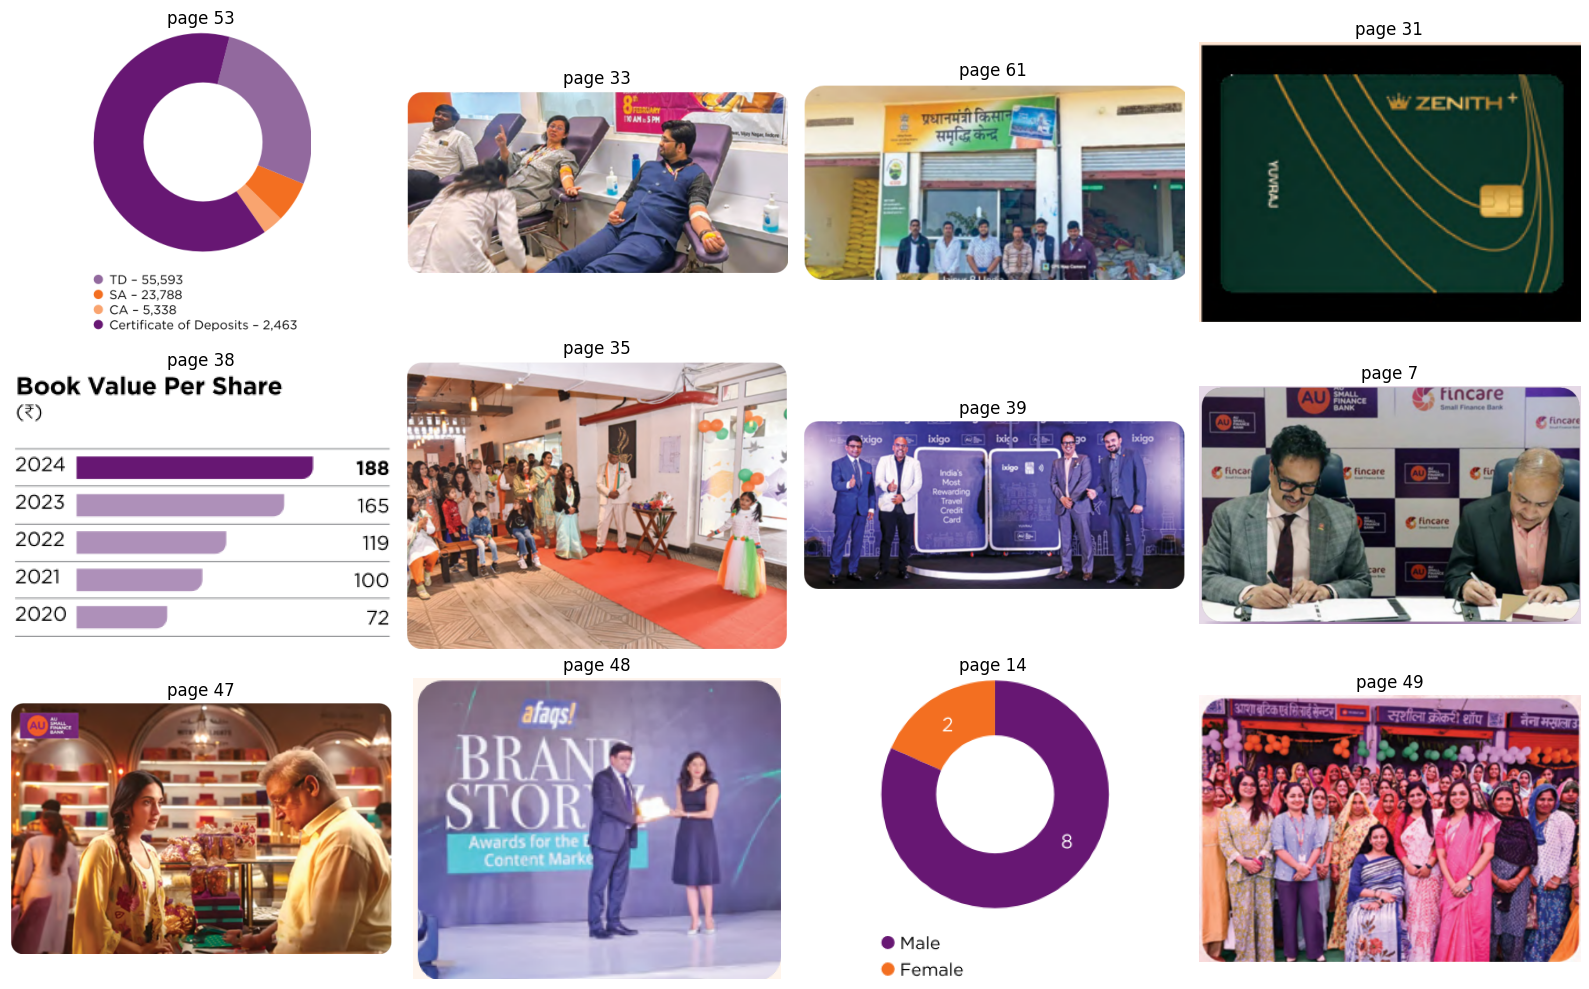

--- page 112, shape [4, 5] ---


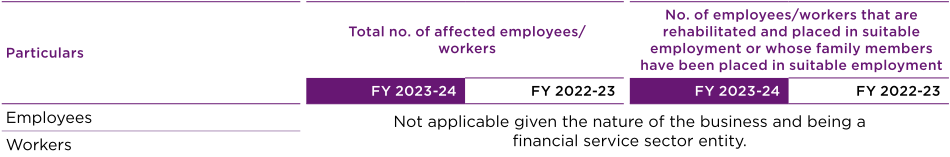

| Particulars   | Total no. of affected employees/ workers - FY 2023-24       | Total no. of affected employees/ workers - FY 2022-23       | No. of employees/workers that are rehabilitated and placed in suitable employment or whose family members have been placed in suitable employment - FY 2023-24   | No. of employees/workers that are rehabilitated and placed in suitable employment or whose family members have been placed in suitable employment - FY 2022-23   |
|---------------|-------------------------------------------------------------|-------------------------------------------------------------|------------------------------------------------------------------------------------------------------------------------------------------------------------------|------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Employees     | Not applicable given the nature of the business and being a | Not applicable given the nature of the business and being a | Not applicable given the nature of the business and being a                                                                                                      | Not applicable given the nature of the business and being a                                                                                                      |
| Workers       | financial service sector entity.                            | financial service sector entity.                            | financial service sector entity.                                                                                                                                 | financial service sector entity.                                                                                                                                 |

--- page 87, shape [6, 3] ---


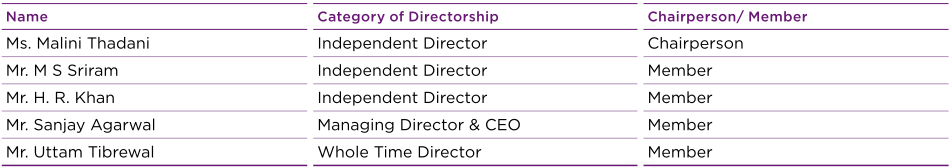

| Name               | Category of Directorship   | Chairperson/ Member   |
|--------------------|----------------------------|-----------------------|
| Ms. Malini Thadani | Independent Director       | Chairperson           |
| Mr. M S Sriram     | Independent Director       | Member                |
| Mr. H. R. Khan     | Independent Director       | Member                |
| Mr. Sanjay Agarwal | Managing Director & CEO    | Member                |
| Mr. Uttam Tibrewal | Whole Time Director        | Member                |

In [18]:
import random, matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

els = json.loads((PROCESSED_DIR / "au_small_finance_bank_2024.json").read_text())

# (a) 12 random kept images: how many are real charts?
imgs = [e for e in els if e["type"] == "image"]
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, e in zip(axes.flat, random.sample(imgs, min(12, len(imgs)))):
    ax.imshow(Image.open(e["image_path"])); ax.set_title(f"page {e['page']}"); ax.axis("off")
plt.tight_layout(); plt.show()

# (b) 2 random tables: compare the Markdown with the table image
for t in random.sample([e for e in els if e["type"] == "table" and e["image_path"]], 2):
    print(f"--- page {t['page']}, shape {t['shape']} ---")
    display(Image.open(t["image_path"]))
    display(Markdown(t["content"][:2000]))